# 14-day cumulative number of COVID-19 cases per 100 000

At the end of the page, we provide a detailed description of how the numbers are calculated.

### Compute data

In [1]:
import datetime as dt
import pandas as pd
pd.set_option("max_rows", None)
from oscovida import get_incidence_rates_countries

## Table for all countries

In [2]:
cases_incidence, deaths_incidence = get_incidence_rates_countries()

Downloaded data: last data point 8/27/20 from https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv
Downloaded data: last data point 8/27/20 from https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_deaths_global.csv


In [3]:
cases_incidence

,14-day-sum,population,14-day-incidence-rate
Country,,,
Afghanistan,698.0,3.892834e+07,1.793038
Albania,1966.0,2.877800e+06,68.316075
Algeria,5352.0,4.385104e+07,12.204955
Andorra,109.0,7.726500e+04,141.072931
Angola,563.0,3.286627e+07,1.713003
Antigua and Barbuda,1.0,9.792800e+04,1.021158
Argentina,97855.0,4.519578e+07,216.513592
Armenia,1971.0,2.963234e+06,66.515166
Australia,2413.0,2.545970e+07,9.477724


## Table sorted by 14-day-incidence

In [4]:
cases_incidence.sort_values(by=['14-day-incidence-rate'], ascending=False)

,14-day-sum,population,14-day-incidence-rate
Country,,,
Maldives,1757.0,5.405420e+05,325.044122
Peru,97082.0,3.297185e+07,294.439080
Bahrain,4704.0,1.701583e+06,276.448460
Colombia,136884.0,5.088288e+07,269.017770
Panama,10580.0,4.314768e+06,245.204377
Brazil,485871.0,2.125594e+08,228.581272
Israel,19323.0,8.655541e+06,223.244278
Argentina,97855.0,4.519578e+07,216.513592
Costa Rica,10361.0,5.094114e+06,203.391601


## Tutorial: Detailed calculation for one country

In [5]:
from oscovida import fetch_cases, get_population
import datetime

In [6]:
period = 14 # Days we compute the incidence rate over

In [7]:
cases = fetch_cases() # Get a DataFrame where each row is the country, and columns cumulative case numbers
cases = cases.groupby(cases.index).sum() # Merge the rows for different regions as we want the numbers for an entire country

In [8]:
cases_germany = cases.loc['Germany'][2:] # First 2 entries are lat/lon so we only take the subsequent ones
cases_germany.tail()

8/23/20    234494.0
8/24/20    236122.0
8/25/20    237583.0
8/26/20    239010.0
8/27/20    240571.0
Name: Germany, dtype: float64

In [9]:
yesterday = datetime.datetime.now() - datetime.timedelta(days=1)
x_days_ago = yesterday - datetime.timedelta(days=period)

In [10]:
period_mask = (
    (yesterday > pd.to_datetime(cases_germany.index)) &
    (pd.to_datetime(cases_germany.index) > x_days_ago)
) # Mask for dates between today and x days ago

In [11]:
cases_in_period_per_day_germany = cases_germany[period_mask].diff() # Apply the period mask and get the diff to get the daily new cases
cases_in_period_per_day_germany

8/14/20       NaN
8/15/20     697.0
8/16/20     519.0
8/17/20    1693.0
8/18/20    1420.0
8/19/20    1586.0
8/20/20    1586.0
8/21/20    1737.0
8/22/20     832.0
8/23/20     633.0
8/24/20    1628.0
8/25/20    1461.0
8/26/20    1427.0
8/27/20    1561.0
Name: Germany, dtype: float64

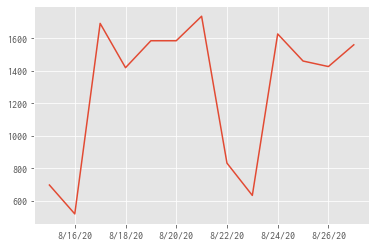

In [12]:
cases_in_period_per_day_germany.plot() # We can easily look at new cases per day

In [13]:
population = get_population().population

In [14]:
population_germany = population.loc['Germany'] # Get the population of Germany
population_germany

83783945.0

In [15]:
incidence_rate_germany = cases_in_period_per_day_germany[-1] / population_germany * 100_000
incidence_rate_germany # By convention this is total cases over period / population * 100_000

1.8631254472440992